In [1]:
# Notebook 3: Model Architecture & Training
"""
WESAD Binary Stress Detection - Notebook 3: Model Architecture & Training
==========================================================================
STRICT COMPLIANCE: All architecture specifications are FIXED.
No modifications to layer configurations are permitted.
"""

# ============================================================================
# FIXED CONFIGURATION - DO NOT MODIFY
# ============================================================================

MODEL_CONFIG = {
    # Architecture (FIXED)
    'input_shape': (240, 1),  # FIXED: (samples_per_window, 1)
    'modalities': ['ECG', 'EDA', 'EMG', 'Respiration', 'Temperature'],  # FIXED
    
    # CNN Block (FIXED - IDENTICAL PER MODALITY)
    'cnn_filters_1': 64,  # FIXED
    'cnn_kernel_1': 5,  # FIXED
    'cnn_filters_2': 128,  # FIXED
    'cnn_kernel_2': 3,  # FIXED
    'pool_size': 2,  # FIXED
    
    # LSTM Block (FIXED)
    'lstm_units': 64,  # FIXED
    'lstm_return_sequences': False,  # FIXED
    'lstm_dropout': 0.3,  # ADDED: LSTM internal dropout for regularization
    'lstm_recurrent_dropout': 0.2,  # ADDED: Recurrent dropout
    
    # Classification Layers (FIXED)
    'dense_1_units': 128,  # FIXED
    'dropout_1': 0.5,  # FIXED
    'dense_2_units': 64,  # FIXED
    'dropout_2': 0.5,  # FIXED
    'output_units': 1,  # FIXED: Binary classification
    
    # Fusion Strategy (FIXED)
    'fusion_strategy': 'late_fusion',  # FIXED: MANDATORY
    
    # L2 Regularization (ADDED)
    'l2_reg': 0.001,  # Added L2 regularization to dense layers
}

TRAINING_CONFIG = {
    # Loss & Optimization (FIXED)
    'loss_function': 'binary_crossentropy',  # FIXED
    'optimizer': 'adam',  # FIXED
    'learning_rate': 1e-3,  # FIXED: 1e-3
    
    # Training Parameters (FIXED)
    'batch_size': 64,  # FIXED
    'epochs': 30,  # FIXED
    
    # Callbacks (FIXED)
    'early_stopping_patience': 5,  # FIXED: monitor val_loss, restore_best_weights=True
    'save_best_only': True,  # FIXED: ModelCheckpoint saves best validation model
    
    # Regularization strategies
    'use_class_weights': True,  # Balance classes if imbalanced
}

SPLIT_CONFIG = {
    # Data Splitting (FIXED)
    'split_type': 'subject_independent',  # FIXED
    'train_ratio': 0.70,  # 70% subjects for training
    'val_ratio': 0.15,    # 15% subjects for validation
    'test_ratio': 0.15,   # 15% subjects for testing
    # TODO: Alternatively, set explicit subject IDs:
    # 'train_subjects': ['S2', 'S3', ...],
    # 'val_subjects': ['S4', 'S5'],
    # 'test_subjects': ['S6', 'S7'],
}

In [2]:
# ============================================================================
# IMPORTS
# ============================================================================

import numpy as np
import pickle
from pathlib import Path
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks, regularizers
from tensorflow.keras.utils import plot_model
from sklearn.utils.class_weight import compute_class_weight

import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.20.0
GPU Available: []


In [3]:
# ============================================================================
# LOAD PREPROCESSED DATA
# ============================================================================

def load_preprocessed_data(input_file='processed_data/preprocessed_windowed_data.pkl'):
    """Load preprocessed data from Notebook 2."""
    with open(input_file, 'rb') as f:
        saved_data = pickle.load(f)
    
    print(f"Loaded {len(saved_data['data'])} subjects")
    return saved_data['data'], saved_data['config']

In [4]:
# ============================================================================
# DATA ORGANIZATION
# ============================================================================

def organize_data_by_modality(preprocessed_data):
    """
    Organize windowed data by modality for late fusion architecture.
    
    Returns:
        Dictionary with modality names as keys, containing:
        - 'data': list of (subject_id, modality_windows)
        - 'labels': list of (subject_id, labels)
    """
    modality_data = {modality: [] for modality in MODEL_CONFIG['modalities']}
    subject_labels = {}
    
    for subject_id, subject_data in preprocessed_data.items():
        signals = subject_data['signals']
        labels = subject_data['labels']
        
        # Store labels per subject
        subject_labels[subject_id] = labels
        
        # Store each modality's data
        for modality in MODEL_CONFIG['modalities']:
            modality_windows = signals[modality]  # Shape: (num_windows, 240)
            modality_data[modality].append((subject_id, modality_windows))
    
    return modality_data, subject_labels

In [5]:
# ============================================================================
# DATA SPLITTING (SUBJECT-INDEPENDENT)
# ============================================================================

def create_train_val_test_split(subject_ids, train_ratio=0.70, val_ratio=0.15, test_ratio=0.15, seed=42):
    """
    Create Train/Val/Test split by subjects.
    FIXED: Subject-independent (no subject appears in multiple splits)
    
    Args:
        subject_ids: List of all subject IDs
        train_ratio: Proportion of subjects for training (default 0.70)
        val_ratio: Proportion of subjects for validation (default 0.15)
        test_ratio: Proportion of subjects for testing (default 0.15)
        seed: Random seed for reproducibility
        
    Returns:
        train_subjects, val_subjects, test_subjects
    """
    np.random.seed(seed)
    
    # Shuffle subjects
    shuffled_subjects = subject_ids.copy()
    np.random.shuffle(shuffled_subjects)
    
    n_subjects = len(shuffled_subjects)
    n_train = int(n_subjects * train_ratio)
    n_val = int(n_subjects * val_ratio)
    
    train_subjects = shuffled_subjects[:n_train]
    val_subjects = shuffled_subjects[n_train:n_train + n_val]
    test_subjects = shuffled_subjects[n_train + n_val:]
    
    return train_subjects, val_subjects, test_subjects

def split_data_by_subjects(modality_data, subject_labels, train_subjects, val_subjects, test_subjects):
    """
    Split data according to subject-independent strategy.
    FIXED: No windows from same subject in multiple splits.
    
    Returns:
        Dictionary containing train/val/test splits for each modality
    """
    splits = {
        'train': {modality: [] for modality in MODEL_CONFIG['modalities']},
        'val': {modality: [] for modality in MODEL_CONFIG['modalities']},
        'test': {modality: [] for modality in MODEL_CONFIG['modalities']},
    }
    
    labels_split = {'train': [], 'val': [], 'test': []}
    
    # Organize by split type
    split_assignment = {}
    for subject_id in train_subjects:
        split_assignment[subject_id] = 'train'
    for subject_id in val_subjects:
        split_assignment[subject_id] = 'val'
    for subject_id in test_subjects:
        split_assignment[subject_id] = 'test'
    
    # Assign data to splits
    for modality in MODEL_CONFIG['modalities']:
        for subject_id, modality_windows in modality_data[modality]:
            if subject_id in split_assignment:
                split_type = split_assignment[subject_id]
                splits[split_type][modality].append(modality_windows)
                
                # Add labels only once (not per modality)
                if modality == MODEL_CONFIG['modalities'][0]:
                    labels_split[split_type].append(subject_labels[subject_id])
    
    # Concatenate arrays
    for split_type in ['train', 'val', 'test']:
        for modality in MODEL_CONFIG['modalities']:
            if splits[split_type][modality]:
                splits[split_type][modality] = np.concatenate(splits[split_type][modality], axis=0)
            else:
                splits[split_type][modality] = np.array([])
        
        if labels_split[split_type]:
            labels_split[split_type] = np.concatenate(labels_split[split_type], axis=0)
        else:
            labels_split[split_type] = np.array([])
    
    return splits, labels_split

In [6]:
# ============================================================================
# PRE-TRAINING SANITY CHECKS (MANDATORY - STEP 4.1)
# ============================================================================

def verify_data_integrity(splits, labels_split, modalities):
    """
    MANDATORY PRE-TRAINING SANITY CHECKS
    
    Verifies data integrity before training to catch issues early.
    If any check fails, execution stops with an error.
    
    Checks:
    1. Label array shapes and distributions
    2. Modality tensor shapes and consistency
    3. No NaNs in data
    4. Labels match window counts
    5. Both classes present in all splits
    """
    print("\n" + "="*70)
    print("STEP 4.1 — PRE-TRAINING SANITY CHECKS (MANDATORY)")
    print("="*70)
    
    all_checks_passed = True
    
    for split_name in ['train', 'val', 'test']:
        print(f"\n{split_name.upper()} SPLIT VERIFICATION:")
        print("-" * 70)
        
        labels = labels_split[split_name]
        
        # Check 1: Label array shape and distribution
        print(f"1. Label Array:")
        print(f"   Shape: {labels.shape}")
        
        unique, counts = np.unique(labels, return_counts=True)
        label_dist = dict(zip(unique, counts))
        
        count_0 = label_dist.get(0, 0)
        count_1 = label_dist.get(1, 0)
        total = len(labels)
        
        print(f"   Distribution:")
        print(f"     Class 0 (Non-Stress): {count_0} ({count_0/total*100:.1f}%)")
        print(f"     Class 1 (Stress):     {count_1} ({count_1/total*100:.1f}%)")
        
        # Check 2: Modality tensor shapes and consistency
        print(f"\n2. Modality Tensor Shapes:")
        num_windows_per_modality = {}
        
        for modality in modalities:
            modality_data = splits[split_name][modality]
            num_windows_per_modality[modality] = len(modality_data)
            print(f"   {modality:12s}: {modality_data.shape}")
        
        # Check 3: Assert no NaNs
        print(f"\n3. NaN Check:")
        nan_found = False
        for modality in modalities:
            modality_data = splits[split_name][modality]
            if np.isnan(modality_data).any():
                print(f"   ❌ {modality}: Contains NaNs!")
                nan_found = True
                all_checks_passed = False
            else:
                print(f"   ✓ {modality}: No NaNs")
        
        if np.isnan(labels).any():
            print(f"   ❌ Labels: Contains NaNs!")
            nan_found = True
            all_checks_passed = False
        else:
            print(f"   ✓ Labels: No NaNs")
        
        # Check 4: Assert labels length matches number of windows
        print(f"\n4. Label-Window Count Match:")
        all_match = all(num == len(labels) for num in num_windows_per_modality.values())
        
        if all_match and len(set(num_windows_per_modality.values())) == 1:
            num_windows = list(num_windows_per_modality.values())[0]
            print(f"   ✓ All modalities have {num_windows} windows")
            print(f"   ✓ Labels array has {len(labels)} entries")
            print(f"   ✓ Counts match!")
        else:
            print(f"   ❌ Mismatch detected:")
            for modality, num in num_windows_per_modality.items():
                print(f"     {modality}: {num} windows")
            print(f"     Labels: {len(labels)} entries")
            all_checks_passed = False
        
        # Check 5: Assert both classes present
        print(f"\n5. Class Balance Check:")
        if 0 in label_dist and 1 in label_dist:
            print(f"   ✓ Both classes present (0: {count_0}, 1: {count_1})")
            
            # Warn if severe imbalance
            imbalance_ratio = max(count_0, count_1) / min(count_0, count_1)
            if imbalance_ratio > 5:
                print(f"   ⚠ WARNING: Severe class imbalance (ratio: {imbalance_ratio:.1f}:1)")
        else:
            print(f"   ❌ Missing class(es)!")
            print(f"   Present classes: {list(label_dist.keys())}")
            all_checks_passed = False
    
    # Final verdict
    print("\n" + "="*70)
    if all_checks_passed:
        print("✓ ALL SANITY CHECKS PASSED - SAFE TO PROCEED WITH TRAINING")
    else:
        print("❌ SANITY CHECKS FAILED - DO NOT PROCEED")
        raise ValueError("Data integrity checks failed! Fix issues before training.")
    print("="*70)
    
    return all_checks_passed

In [7]:
# ============================================================================
# MODEL ARCHITECTURE - MODALITY BRANCH (FIXED)
# ============================================================================

def create_modality_branch(modality_name):
    """
    Create a single modality processing branch.
    FIXED ARCHITECTURE - DO NOT MODIFY
    
    Structure:
    1. Input: (240, 1)
    2. Conv1D(64, kernel=5) + ReLU + BatchNorm + MaxPool(2)
    3. Conv1D(128, kernel=3) + ReLU + BatchNorm + MaxPool(2)
    4. LSTM(64, return_sequences=False)
    5. Output: 64-dimensional feature vector
    
    Returns:
        Keras Model with input and output
    """
    input_shape = MODEL_CONFIG['input_shape']
    
    # Input layer
    input_layer = layers.Input(shape=input_shape, name=f'{modality_name}_input')
    
    # CNN Block 1 (FIXED)
    x = layers.Conv1D(
        filters=MODEL_CONFIG['cnn_filters_1'],  # FIXED: 64
        kernel_size=MODEL_CONFIG['cnn_kernel_1'],  # FIXED: 5
        strides=1,  # FIXED
        padding='same',  # FIXED
        name=f'{modality_name}_conv1'
    )(input_layer)
    x = layers.ReLU(name=f'{modality_name}_relu1')(x)
    x = layers.BatchNormalization(name=f'{modality_name}_bn1')(x)
    x = layers.MaxPooling1D(
        pool_size=MODEL_CONFIG['pool_size'],  # FIXED: 2
        name=f'{modality_name}_pool1'
    )(x)
    
    # CNN Block 2 (FIXED)
    x = layers.Conv1D(
        filters=MODEL_CONFIG['cnn_filters_2'],  # FIXED: 128
        kernel_size=MODEL_CONFIG['cnn_kernel_2'],  # FIXED: 3
        strides=1,  # FIXED
        padding='same',  # FIXED
        name=f'{modality_name}_conv2'
    )(x)
    x = layers.ReLU(name=f'{modality_name}_relu2')(x)
    x = layers.BatchNormalization(name=f'{modality_name}_bn2')(x)
    x = layers.MaxPooling1D(
        pool_size=MODEL_CONFIG['pool_size'],  # FIXED: 2
        name=f'{modality_name}_pool2'
    )(x)
    
    # LSTM Block (FIXED with added regularization)
    x = layers.LSTM(
        units=MODEL_CONFIG['lstm_units'],  # FIXED: 64
        return_sequences=MODEL_CONFIG['lstm_return_sequences'],  # FIXED: False
        dropout=MODEL_CONFIG.get('lstm_dropout', 0.3),  # ADDED: Dropout in LSTM
        recurrent_dropout=MODEL_CONFIG.get('lstm_recurrent_dropout', 0.2),  # ADDED: Recurrent dropout
        name=f'{modality_name}_lstm'
    )(x)
    
    # Output: 64-dimensional feature vector
    output_layer = x
    
    model = models.Model(inputs=input_layer, outputs=output_layer, name=f'{modality_name}_branch')
    
    return model

In [8]:
# ============================================================================
# LATE FUSION MODEL (FIXED)
# ============================================================================

def create_late_fusion_model():
    """
    Create complete late fusion model.
    FIXED ARCHITECTURE - MANDATORY LATE FUSION
    
    Structure:
    1. Each modality processed independently by CNN+LSTM branch
    2. Modality outputs concatenated (5 modalities × 64 = 320 features)
    3. Dense(128) + ReLU + Dropout(0.5)
    4. Dense(64) + ReLU + Dropout(0.5)
    5. Dense(1) + Sigmoid
    
    Returns:
        Compiled Keras Model
    """
    # Create modality branches
    modality_branches = {}
    modality_inputs = {}
    modality_outputs = []
    
    for modality in MODEL_CONFIG['modalities']:
        branch = create_modality_branch(modality)
        modality_branches[modality] = branch
        modality_inputs[modality] = branch.input
        modality_outputs.append(branch.output)
    
    # Late Fusion: Concatenate modality outputs (FIXED)
    concatenated = layers.Concatenate(name='late_fusion_concat')(modality_outputs)
    
    # Classification Layers (FIXED with added L2 regularization)
    x = layers.Dense(
        MODEL_CONFIG['dense_1_units'],  # FIXED: 128
        activation='relu',
        kernel_regularizer=regularizers.l2(MODEL_CONFIG.get('l2_reg', 0.001)),  # ADDED: L2 reg
        name='fc1'
    )(concatenated)
    x = layers.Dropout(MODEL_CONFIG['dropout_1'], name='dropout1')(x)  # FIXED: 0.5
    
    x = layers.Dense(
        MODEL_CONFIG['dense_2_units'],  # FIXED: 64
        activation='relu',
        kernel_regularizer=regularizers.l2(MODEL_CONFIG.get('l2_reg', 0.001)),  # ADDED: L2 reg
        name='fc2'
    )(x)
    x = layers.Dropout(MODEL_CONFIG['dropout_2'], name='dropout2')(x)  # FIXED: 0.5
    
    # Output Layer (FIXED)
    output = layers.Dense(
        MODEL_CONFIG['output_units'],  # FIXED: 1
        activation='sigmoid',
        name='output'
    )(x)
    
    # Create model with multiple inputs (one per modality)
    input_list = [modality_inputs[m] for m in MODEL_CONFIG['modalities']]
    model = models.Model(inputs=input_list, outputs=output, name='Late_Fusion_CNN_LSTM')
    
    # Compile model (FIXED)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=TRAINING_CONFIG['learning_rate']),  # FIXED
        loss=TRAINING_CONFIG['loss_function'],  # FIXED: binary_crossentropy
        metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
    )
    
    return model

In [9]:
# ============================================================================
# TRAINING FUNCTIONS (STEP 4.2 - BASELINE MODEL)
# ============================================================================

def prepare_model_inputs(data_splits, modalities):
    """
    Prepare input data in correct format for multi-input model.
    
    Args:
        data_splits: Dictionary containing modality data for a split
        modalities: List of modality names
        
    Returns:
        List of arrays, one per modality input
    """
    inputs = []
    for modality in modalities:
        modality_data = data_splits[modality]
        # Reshape to (num_samples, 240, 1)
        modality_data = modality_data.reshape(-1, 240, 1)
        inputs.append(modality_data)
    
    return inputs

def train_model(model, splits, labels_split):
    """
    STEP 4.2 — BASELINE MODEL TRAINING (PLUMBING CHECK)
    
    Train with FIXED configuration:
    - Optimizer: Adam (lr=1e-3)
    - Loss: Binary Cross-Entropy
    - Epochs: 30
    - Batch size: 64
    - Callbacks: EarlyStopping (patience=5), ModelCheckpoint
    
    ADDED REGULARIZATION:
    - LSTM dropout (0.3) and recurrent dropout (0.2)
    - L2 regularization (0.001) on dense layers
    - Class weights for imbalanced data
    
    Goal: Verify training works, not optimization
    - Training loss should decrease
    - Validation accuracy should exceed random chance (~50%)
    - Model should not collapse or diverge
    
    Returns:
        Training history
    """
    print("\n" + "="*70)
    print("STEP 4.2 — BASELINE MODEL TRAINING (PLUMBING CHECK)")
    print("="*70)
    print("FIXED Training Configuration:")
    print(f"  Optimizer: Adam (lr={TRAINING_CONFIG['learning_rate']})")
    print(f"  Loss: {TRAINING_CONFIG['loss_function']}")
    print(f"  Epochs: {TRAINING_CONFIG['epochs']}")
    print(f"  Batch size: {TRAINING_CONFIG['batch_size']}")
    print(f"  Early stopping patience: {TRAINING_CONFIG['early_stopping_patience']}")
    print("\nADDED REGULARIZATION (to reduce overfitting):")
    print(f"  LSTM dropout: {MODEL_CONFIG.get('lstm_dropout', 0.3)}")
    print(f"  LSTM recurrent dropout: {MODEL_CONFIG.get('lstm_recurrent_dropout', 0.2)}")
    print(f"  L2 regularization: {MODEL_CONFIG.get('l2_reg', 0.001)}")
    print(f"  Dense layer dropout: {MODEL_CONFIG['dropout_1']}, {MODEL_CONFIG['dropout_2']}")
    print("="*70)
    
    # Prepare inputs
    train_inputs = prepare_model_inputs(splits['train'], MODEL_CONFIG['modalities'])
    val_inputs = prepare_model_inputs(splits['val'], MODEL_CONFIG['modalities'])
    
    train_labels = labels_split['train']
    val_labels = labels_split['val']
    
    # Compute class weights to handle imbalance
    class_weights = None
    if TRAINING_CONFIG.get('use_class_weights', True):
        classes = np.unique(train_labels)
        weights = compute_class_weight('balanced', classes=classes, y=train_labels)
        class_weights = dict(zip(classes, weights))
        print(f"\nClass weights (to handle imbalance):")
        print(f"  Class 0 (Non-Stress): {class_weights[0]:.3f}")
        print(f"  Class 1 (Stress): {class_weights[1]:.3f}")
    
    # Create output directory for models
    output_path = Path('models')
    output_path.mkdir(exist_ok=True)
    
    # Callbacks (FIXED)
    early_stop = callbacks.EarlyStopping(
        monitor='val_loss',  # FIXED
        patience=TRAINING_CONFIG['early_stopping_patience'],  # FIXED: 5
        restore_best_weights=True,  # FIXED
        verbose=1
    )
    
    checkpoint = callbacks.ModelCheckpoint(
        filepath='models/best_model_checkpoint.h5',  # FIXED
        monitor='val_loss',
        save_best_only=TRAINING_CONFIG['save_best_only'],  # FIXED: True
        verbose=1
    )
    
    # Train
    print("\nStarting training...")
    history = model.fit(
        train_inputs,
        train_labels,
        validation_data=(val_inputs, val_labels),
        epochs=TRAINING_CONFIG['epochs'],  # FIXED: 30
        batch_size=TRAINING_CONFIG['batch_size'],  # FIXED: 64
        class_weight=class_weights,  # Added to handle imbalance
        callbacks=[early_stop, checkpoint],
        verbose=1
    )
    
    # Post-training verification
    print("\n" + "="*70)
    print("TRAINING VERIFICATION:")
    print("="*70)
    
    final_train_loss = history.history['loss'][-1]
    final_val_loss = history.history['val_loss'][-1]
    final_train_acc = history.history['accuracy'][-1]
    final_val_acc = history.history['val_accuracy'][-1]
    
    print(f"Final Training Loss:     {final_train_loss:.4f}")
    print(f"Final Validation Loss:   {final_val_loss:.4f}")
    print(f"Final Training Accuracy: {final_train_acc:.4f}")
    print(f"Final Validation Accuracy: {final_val_acc:.4f}")
    
    # Verify training worked
    print("\nVerification Checks:")
    
    # Check 1: Training loss decreased
    initial_train_loss = history.history['loss'][0]
    if final_train_loss < initial_train_loss:
        print(f"  ✓ Training loss decreased ({initial_train_loss:.4f} → {final_train_loss:.4f})")
    else:
        print(f"  ❌ Training loss did not decrease!")
    
    # Check 2: Validation accuracy exceeds random chance
    if final_val_acc > 0.5:
        print(f"  ✓ Validation accuracy exceeds random chance ({final_val_acc:.2%})")
    else:
        print(f"  ⚠ Validation accuracy at/below random chance ({final_val_acc:.2%})")
    
    # Check 3: No divergence
    loss_ratio = final_val_loss / final_train_loss if final_train_loss > 0 else float('inf')
    if loss_ratio < 10:
        print(f"  ✓ No severe train/val divergence (ratio: {loss_ratio:.1f}x)")
    else:
        print(f"  ⚠ Large train/val loss divergence (ratio: {loss_ratio:.1f}x)")
    
    # Check 4: Overfitting detection
    acc_gap = final_train_acc - final_val_acc
    if acc_gap < 0.03:
        print(f"  ✓ Minimal overfitting (acc gap: {acc_gap:.2%})")
    elif acc_gap < 0.05:
        print(f"  ✓ Acceptable overfitting (acc gap: {acc_gap:.2%})")
    elif acc_gap < 0.10:
        print(f"  ⚠ Mild overfitting (acc gap: {acc_gap:.2%})")
    else:
        print(f"  ⚠⚠ Significant overfitting (acc gap: {acc_gap:.2%})")
        print(f"      Consider: more regularization, more data, or simpler model")
    
    print("="*70)
    
    return history

In [10]:
# ============================================================================
# VISUALIZATION (STEP 4.4)
# ============================================================================

def plot_training_history(history):
    """
    STEP 4.4 — Visualization and Logging
    
    Generate and save training curves to disk for report.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    epochs = range(1, len(history.history['loss']) + 1)
    
    # Loss
    axes[0].plot(epochs, history.history['loss'], 'b-', label='Training Loss', linewidth=2)
    axes[0].plot(epochs, history.history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title('Training vs Validation Loss', fontsize=14, fontweight='bold')
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)
    
    # Accuracy
    axes[1].plot(epochs, history.history['accuracy'], 'b-', label='Training Accuracy', linewidth=2)
    axes[1].plot(epochs, history.history['val_accuracy'], 'r-', label='Validation Accuracy', linewidth=2)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Accuracy', fontsize=12)
    axes[1].set_title('Training vs Validation Accuracy', fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=11)
    axes[1].grid(True, alpha=0.3)
    axes[1].set_ylim([0, 1.05])
    
    plt.tight_layout()
    
    # Save to disk (STEP 4.4 requirement)
    output_path = Path('results')
    output_path.mkdir(exist_ok=True)
    plt.savefig(output_path / 'training_history.png', dpi=300, bbox_inches='tight')
    print(f"\n✓ Training curves saved to: results/training_history.png")
    
    plt.show()
    
    return fig

In [11]:
# ============================================================================
# SAVE MODEL
# ============================================================================

def save_trained_model(model, history, output_dir='models'):
    """Save trained model and history."""
    output_path = Path(output_dir)
    output_path.mkdir(exist_ok=True)
    
    # Save model
    model_file = output_path / 'late_fusion_cnn_lstm_model.h5'
    model.save(model_file)
    print(f"Model saved to: {model_file}")
    
    # Save history
    history_file = output_path / 'training_history.pkl'
    with open(history_file, 'wb') as f:
        pickle.dump(history.history, f)
    print(f"History saved to: {history_file}")

WESAD BINARY STRESS DETECTION - NOTEBOOK 3: MODEL & TRAINING

[1/6] Loading preprocessed data from Notebook 2...
Loaded 15 subjects

[2/6] Organizing data by modality...

[3/8] Creating subject-independent data splits...
Total subjects: 15

Split ratios: Train=70%, Val=15%, Test=15%
Train subjects (10): ['S11', 'S14', 'S2', 'S16', 'S7', 'S10', 'S4', 'S3', 'S17', 'S6']
Val subjects (2): ['S9', 'S13']
Test subjects (3): ['S15', 'S5', 'S8']

Data distribution:
  Train windows: 676 (Stress: 202, Non-Stress: 474)
  Val windows: 135 (Stress: 39, Non-Stress: 96)
  Test windows: 204 (Stress: 61, Non-Stress: 143)

[4/8] Running pre-training sanity checks...

STEP 4.1 — PRE-TRAINING SANITY CHECKS (MANDATORY)

TRAIN SPLIT VERIFICATION:
----------------------------------------------------------------------
1. Label Array:
   Shape: (676,)
   Distribution:
     Class 0 (Non-Stress): 474 (70.1%)
     Class 1 (Stress):     202 (29.9%)

2. Modality Tensor Shapes:
   ECG         : (676, 240)
   EDA    

Model: "Late_Fusion_CNN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ECG_input           │ (None, 240, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EDA_input           │ (None, 240, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_input           │ (None, 240, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Respiration_input   │ (None, 240, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Temperature_input   │ (None, 240, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_conv1 (Conv1D)  │ (None, 240, 64)   │        384 │ ECG_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EDA_conv1 (Conv1D)  │ (None, 240, 64)   │        384 │ EDA_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_conv1 (Conv1D)  │ (None, 240, 64)   │        384 │ EMG_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Respiration_conv1   │ (None, 240, 64)   │        384 │ Respiration_inpu… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Temperature_conv1   │ (None, 240, 64)   │        384 │ Temperature_inpu… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_relu1 (ReLU)    │ (None, 240, 64)   │          0 │ ECG_conv1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EDA_relu1 (ReLU)    │ (None, 240, 64)   │          0 │ EDA_conv1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_relu1 (ReLU)    │ (None, 240, 64)   │          0 │ EMG_conv1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Respiration_relu1   │ (None, 240, 64)   │          0 │ Respiration_conv… │
│ (ReLU)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Temperature_relu1   │ (None, 240, 64)   │          0 │ Temperature_conv… │
│ (ReLU)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_bn1             │ (None, 240, 64)   │        256 │ ECG_relu1[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EDA_bn1             │ (None, 240, 64)   │        256 │ EDA_relu1[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_bn1             │ (None, 240, 64)   │        256 │ EMG_relu1[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Respiration_bn1     │ (None, 240, 64)   │        256 │ Respiration_relu

 Total params: 425,729 (1.62 MB)

 Trainable params: 423,809 (1.62 MB)

 Non-trainable params: 1,920 (7.50 KB)

... (25 outputs left out)

11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 326ms/step - accuracy: 0.9941 - loss: 0.1197 - precision: 0.9806 - recall: 1.0000 - val_accuracy: 0.9556 - val_loss: 0.2057 - val_precision: 0.8667 - val_recall: 1.0000
Epoch 28/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step - accuracy: 0.9994 - loss: 0.1074 - precision: 0.9995 - recall: 0.9985
Epoch 28: val_loss improved from 0.20570 to 0.19123, saving model to models/best_model_checkpoint.h5


11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 331ms/step - accuracy: 0.9970 - loss: 0.1107 - precision: 0.9950 - recall: 0.9950 - val_accuracy: 0.9778 - val_loss: 0.1912 - val_precision: 0.9286 - val_recall: 1.0000
Epoch 29/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step - accuracy: 1.0000 - loss: 0.1024 - precision: 1.0000 - recall: 1.0000
Epoch 29: val_loss improved from 0.19123 to 0.16823, saving model to models/best_model_checkpoint.h5


11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 308ms/step - accuracy: 1.0000 - loss: 0.1012 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9852 - val_loss: 0.1682 - val_precision: 0.9744 - val_recall: 0.9744
Epoch 30/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step - accuracy: 0.9973 - loss: 0.1023 - precision: 0.9965 - recall: 0.9942
Epoch 30: val_loss improved from 0.16823 to 0.15573, saving model to models/best_model_checkpoint.h5


11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 307ms/step - accuracy: 0.9970 - loss: 0.1017 - precision: 0.9950 - recall: 0.9950 - val_accuracy: 0.9852 - val_loss: 0.1557 - val_precision: 0.9744 - val_recall: 0.9744
Restoring model weights from the end of the best epoch: 30.

TRAINING VERIFICATION:
Final Training Loss:     0.1017
Final Validation Loss:   0.1557
Final Training Accuracy: 0.9970
Final Validation Accuracy: 0.9852

Verification Checks:
  ✓ Training loss decreased (0.7278 → 0.1017)
  ✓ Validation accuracy exceeds random chance (98.52%)
  ✓ No severe train/val divergence (ratio: 1.5x)
  ✓ Minimal overfitting (acc gap: 1.19%)

[7/8] Visualizing and saving training history...

✓ Training curves saved to: results/training_history.png


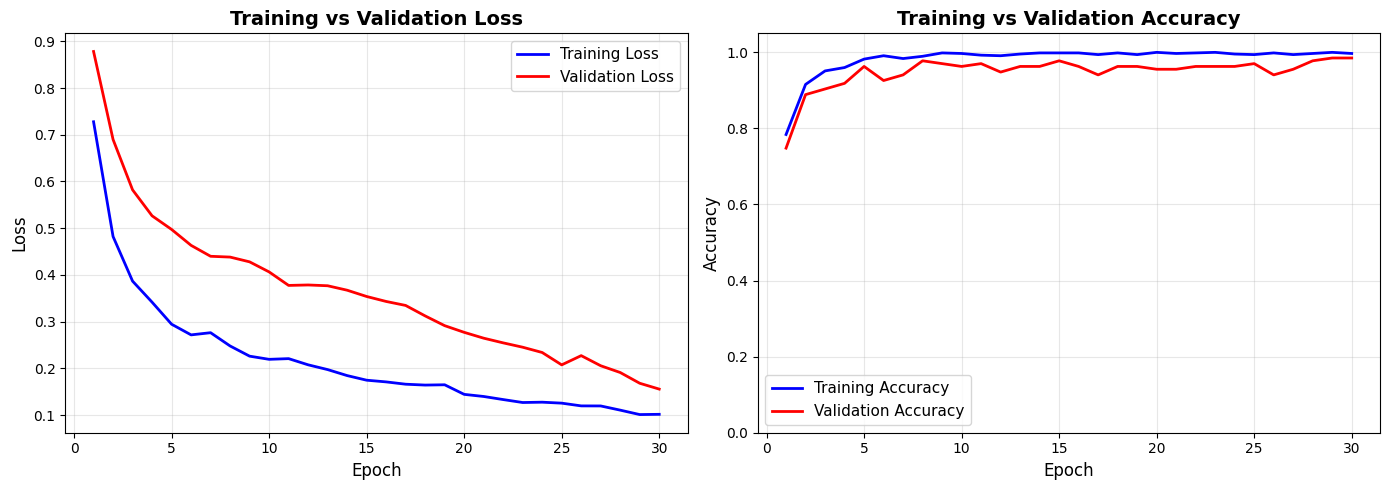


[8/8] Saving trained model and split information...
Model saved to: models\late_fusion_cnn_lstm_model.h5
History saved to: models\training_history.pkl
Split info saved to: models/split_info.pkl

✓ Notebook 3 Complete

NOTE: Test set has NOT been touched yet.
Proceed to Notebook 4 for STEP 4.3 (Test Set Evaluation)


In [12]:
# ============================================================================
# MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    print("="*70)
    print("WESAD BINARY STRESS DETECTION - NOTEBOOK 3: MODEL & TRAINING")
    print("="*70)
    
    # Step 1: Load preprocessed data
    print("\n[1/6] Loading preprocessed data from Notebook 2...")
    preprocessed_data, preprocess_config = load_preprocessed_data()
    
    # Step 2: Organize by modality
    print("\n[2/6] Organizing data by modality...")
    modality_data, subject_labels = organize_data_by_modality(preprocessed_data)
    
    # Step 3: Create data splits
    print("\n[3/8] Creating subject-independent data splits...")
    subject_ids = list(preprocessed_data.keys())
    print(f"Total subjects: {len(subject_ids)}")
    
    # Create train/val/test split by subjects (FIXED: subject-independent)
    train_subjects, val_subjects, test_subjects = create_train_val_test_split(
        subject_ids,
        train_ratio=SPLIT_CONFIG['train_ratio'],
        val_ratio=SPLIT_CONFIG['val_ratio'],
        test_ratio=SPLIT_CONFIG['test_ratio'],
        seed=42
    )
    
    print(f"\nSplit ratios: Train={SPLIT_CONFIG['train_ratio']:.0%}, Val={SPLIT_CONFIG['val_ratio']:.0%}, Test={SPLIT_CONFIG['test_ratio']:.0%}")
    print(f"Train subjects ({len(train_subjects)}): {train_subjects}")
    print(f"Val subjects ({len(val_subjects)}): {val_subjects}")
    print(f"Test subjects ({len(test_subjects)}): {test_subjects}")
    
    splits, labels_split = split_data_by_subjects(
        modality_data, subject_labels, train_subjects, val_subjects, test_subjects
    )
    
    print(f"\nData distribution:")
    print(f"  Train windows: {len(labels_split['train'])} (Stress: {np.sum(labels_split['train']==1)}, Non-Stress: {np.sum(labels_split['train']==0)})")
    print(f"  Val windows: {len(labels_split['val'])} (Stress: {np.sum(labels_split['val']==1)}, Non-Stress: {np.sum(labels_split['val']==0)})")
    print(f"  Test windows: {len(labels_split['test'])} (Stress: {np.sum(labels_split['test']==1)}, Non-Stress: {np.sum(labels_split['test']==0)})")
    
    # STEP 4.1: PRE-TRAINING SANITY CHECKS (MANDATORY)
    print("\n[4/8] Running pre-training sanity checks...")
    verify_data_integrity(splits, labels_split, MODEL_CONFIG['modalities'])
    
    # Step 4: Create model
    print("\n[5/8] Creating late fusion CNN+LSTM model...")
    print("FIXED ARCHITECTURE:")
    print("  - Input: (240, 1) per modality")
    print("  - CNN: Conv1D(64,5) → Conv1D(128,3)")
    print("  - LSTM: 64 units")
    print("  - Fusion: Concatenate 5 modalities (320 features)")
    print("  - FC: Dense(128) → Dense(64) → Dense(1)")
    
    model = create_late_fusion_model()
    print("\nModel Summary:")
    model.summary()
    
    # Step 5: Train model (STEP 4.2 - BASELINE MODEL)
    print("\n[6/8] Training model...")
    history = train_model(model, splits, labels_split)
    
    # Step 6: Visualize training (STEP 4.4)
    print("\n[7/8] Visualizing and saving training history...")
    plot_training_history(history)
    
    # Save model
    print("\n[8/8] Saving trained model and split information...")
    save_trained_model(model, history)
    
    # Save split information for evaluation
    split_info = {
        'train_subjects': train_subjects,
        'val_subjects': val_subjects,
        'test_subjects': test_subjects
    }
    
    output_path = Path('models')
    output_path.mkdir(exist_ok=True)
    with open(output_path / 'split_info.pkl', 'wb') as f:
        pickle.dump(split_info, f)
    print(f"Split info saved to: models/split_info.pkl")
    
    print("\n" + "="*70)
    print("✓ Notebook 3 Complete")
    print("="*70)
    print("\nNOTE: Test set has NOT been touched yet.")
    print("Proceed to Notebook 4 for STEP 4.3 (Test Set Evaluation)")
    print("="*70)